<a href="https://colab.research.google.com/github/Shamit-butterchicken/HealthcareAnalytics_lifeexpectancy_PredictiveModel/blob/main/lab3_shamittripathi_drYoungBlood_healthcareAnalytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

# Task 1: Read raw data
df = pd.read_csv('Life_Expectancy_Data-Update2026.csv')

# Strip white space from column names
df.columns = df.columns.str.strip()

# Output dataset structure
print("Dataset Shape:", df.shape)
print("\nMissing Values per Column:")
print(df.isnull().sum())

df.head()

Dataset Shape: (2938, 22)

Missing Values per Column:
Country                           0
Year                              0
Status                            0
LifeExpectancy                   10
AdultMortality                   10
InfantDeaths                      0
Alcohol                         194
PercentageExpenditure             0
HepatitisB                      553
Measles                           0
BMI                              34
UnderFiveDeaths                   0
Polio                            19
TotalExpenditure                226
Diphtheria                       19
HIV/AIDS                          0
GDP                             448
Population                      652
Thinness1-19Years                34
Thinness5-9Years                 34
IncomeCompositionOfResources    167
Schooling                       163
dtype: int64


,Country,Year,Status,LifeExpectancy,AdultMortality,InfantDeaths,Alcohol,PercentageExpenditure,HepatitisB,Measles,...,Polio,TotalExpenditure,Diphtheria,HIV/AIDS,GDP,Population,Thinness1-19Years,Thinness5-9Years,IncomeCompositionOfResources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


The raw dataset consists of 2,938 rows and 22 columns containing country-level public health metrics. Column headers were cleaned to strip leading/trailing spaces. Initial inspection reveals missing values across several numeric features, including LifeExpectancy, Alcohol, TotalExpenditure, GDP, and Population.

In [ ]:
# Task 2: Data Cleaning & Preprocessing

# 1. Create a copy of the raw DataFrame
df_clean = df.copy()

# 2. Convert categorical variable 'Status' into binary numerical values (Developing=0, Developed=1)
df_clean['Status'] = df_clean['Status'].map({'Developing': 0, 'Developed': 1})

# 3. Identify all numeric features
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns

# 4. Impute missing numeric values using country-level median, with dataset median fallback
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean.groupby('Country')[col].transform('median'))
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# 5. Verify that all missing values have been resolved
print("Remaining missing values across entire dataset:", df_clean.isnull().sum().sum())
print("Cleaned Dataset Shape:", df_clean.shape)

Remaining missing values across entire dataset: 0
Cleaned Dataset Shape: (2938, 22)


Data cleaning was performed using targeted median imputation rather than dropping incomplete rows. Missing numerical metrics were first imputed using the median value calculated for each specific country across available years. For metrics where a country lacked data across all years, the overall dataset median for that feature was used as a fallback. Additionally, the categorical column Status was converted into a binary numerical indicator (
0
0 for Developing,
1
1 for Developed). This methodology resolves all missing entries while retaining all 2,938 observations for downstream modeling.

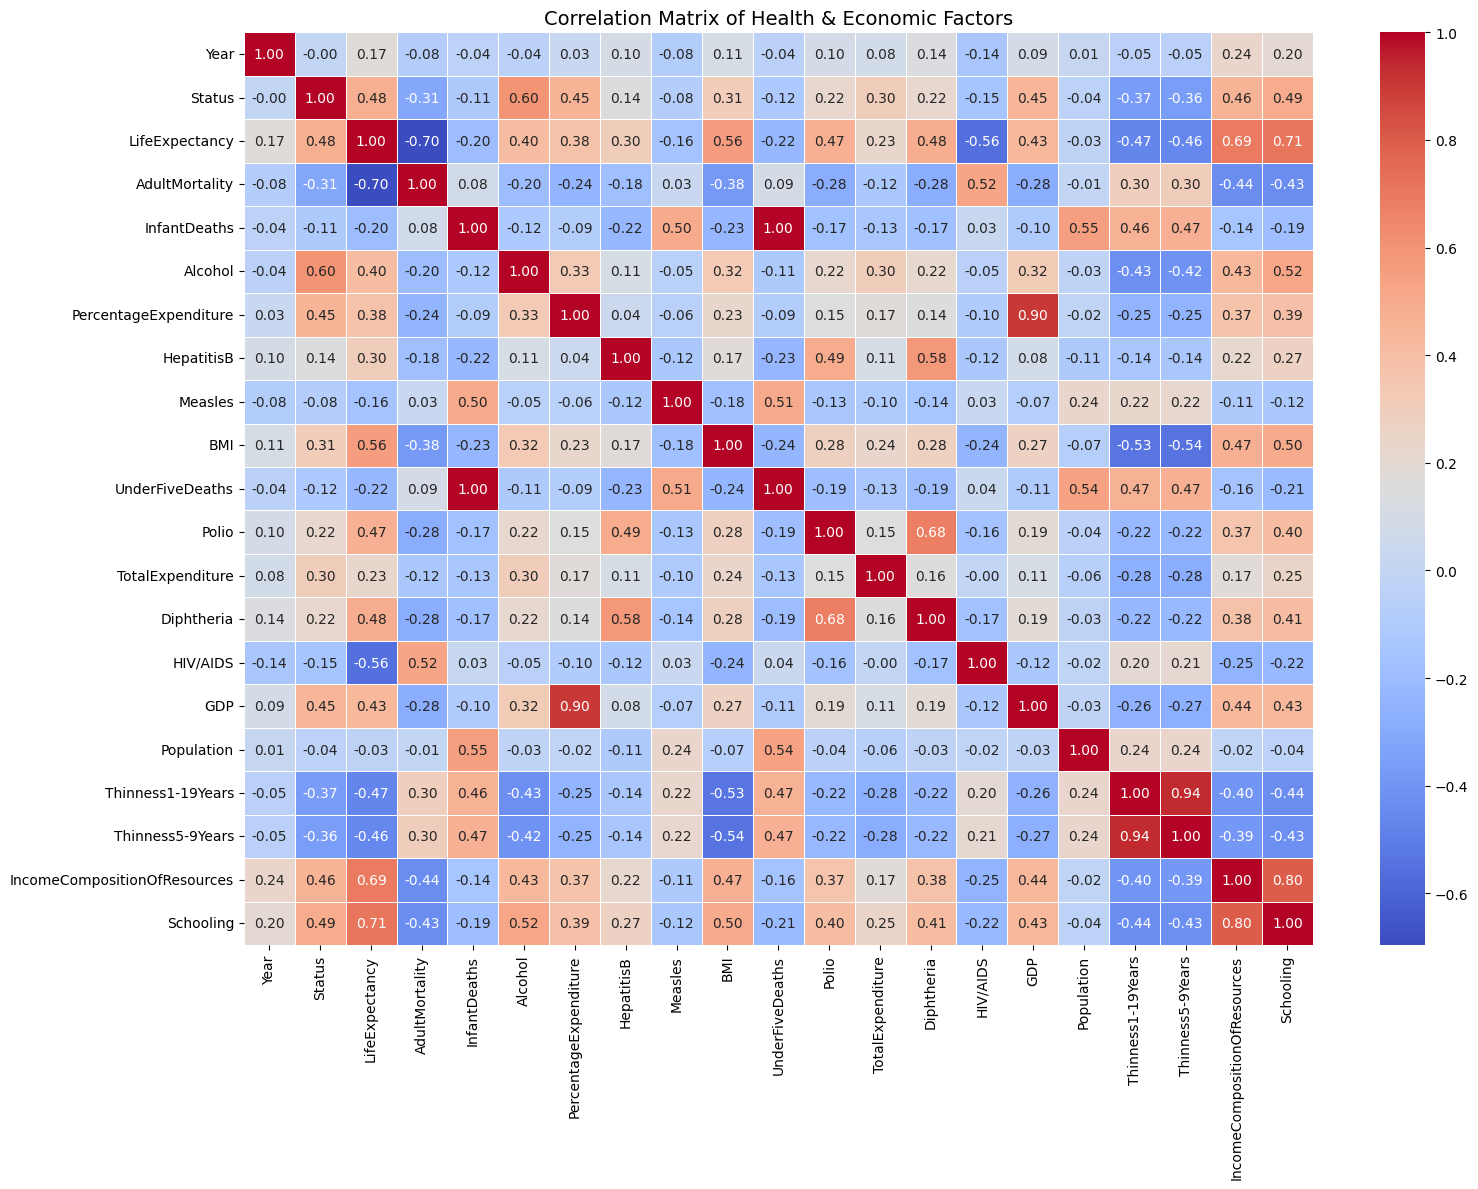

In [ ]:
# Task 3: Correlation Matrix & Heatmap

# 1. Drop text identifier columns (Country) so only numeric features remain
numeric_df = df_clean.drop(columns=['Country'])

# 2. Compute Pearson correlation coefficients between all pairs of numeric variables
corr_matrix = numeric_df.corr()

# 3. Set figure window size (width=16 inches, height=12 inches)
plt.figure(figsize=(16, 12))

# 4. Draw heatmap with annotated values and red/blue color gradient
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    linewidths=0.5
)

# 5. Add chart title and display plot
plt.title('Correlation Matrix of Health & Economic Factors', fontsize=14)
plt.tight_layout()
plt.show()

### Task 3: Correlation Matrix & Heatmap Interpretation

The correlation matrix reveals several key relationships between public health indicators, socio-economic factors, and life expectancy:

* **Strongest Positive Factors**: `Schooling` displays the strongest positive correlation with `LifeExpectancy` (r = 0.71), closely followed by `IncomeCompositionOfResources` (r = 0.69) and `BMI` (r = 0.56). This indicates that higher educational attainment, socio-economic development, and basic nutritional adequacy strongly align with longer population lifespans.
* **Strongest Negative Factors**: `AdultMortality` shows the strongest negative correlation with `LifeExpectancy` (r = -0.70), followed by `HIV/AIDS` prevalence (r = -0.56) and youth thinness metrics (r = -0.47). High adult death rates and infectious disease burdens drastically reduce a population's overall average lifespan.
* **Weak/Negligible Indicators**: Total population size shows virtually no linear relationship with `LifeExpectancy` (r = -0.03), demonstrating that a country's population size is not a primary factor in determining overall lifespan.

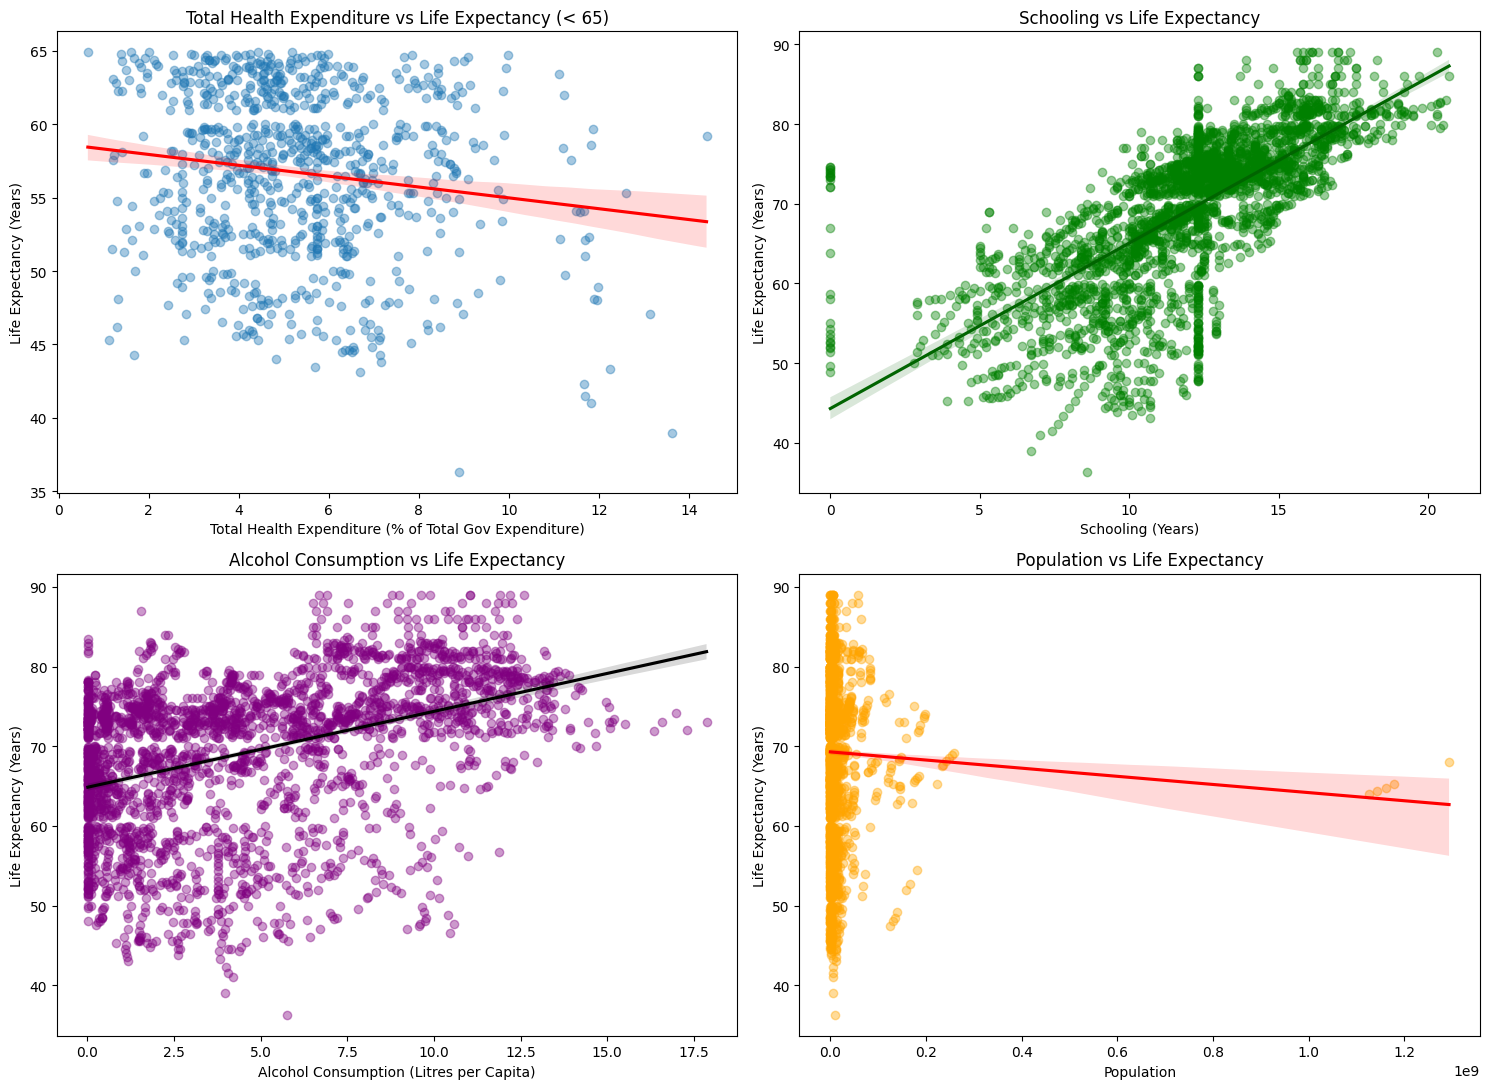

In [ ]:
# Task 4: Generate Scatter Plots for Key Public Health Questions

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Healthcare Expenditure for Low Life Expectancy Countries (< 65)
low_le = df_clean[df_clean['LifeExpectancy'] < 65]
sns.regplot(
    data=low_le,
    x='TotalExpenditure',
    y='LifeExpectancy',
    ax=axes[0, 0],
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)
axes[0, 0].set_title('Total Health Expenditure vs Life Expectancy (< 65)', fontsize=12)
axes[0, 0].set_xlabel('Total Health Expenditure (% of Total Gov Expenditure)')
axes[0, 0].set_ylabel('Life Expectancy (Years)')

# 2. Impact of Schooling on Life Expectancy
sns.regplot(
    data=df_clean,
    x='Schooling',
    y='LifeExpectancy',
    ax=axes[0, 1],
    color='green',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'darkgreen'}
)
axes[0, 1].set_title('Schooling vs Life Expectancy', fontsize=12)
axes[0, 1].set_xlabel('Schooling (Years)')
axes[0, 1].set_ylabel('Life Expectancy (Years)')

# 3. Alcohol Consumption vs Life Expectancy
sns.regplot(
    data=df_clean,
    x='Alcohol',
    y='LifeExpectancy',
    ax=axes[1, 0],
    color='purple',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'black'}
)
axes[1, 0].set_title('Alcohol Consumption vs Life Expectancy', fontsize=12)
axes[1, 0].set_xlabel('Alcohol Consumption (Litres per Capita)')
axes[1, 0].set_ylabel('Life Expectancy (Years)')

# 4. Population vs Life Expectancy
sns.regplot(
    data=df_clean,
    x='Population',
    y='LifeExpectancy',
    ax=axes[1, 1],
    color='orange',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)
axes[1, 1].set_title('Population vs Life Expectancy', fontsize=12)
axes[1, 1].set_xlabel('Population')
axes[1, 1].set_ylabel('Life Expectancy (Years)')

plt.tight_layout()
plt.show()

### Task 4: Analysis of Key Public Health Questions

1. **Healthcare Spending for Low Life Expectancy Countries (< 65)**:
   Simply increasing healthcare expenditure as a percentage of government spending does not automatically guarantee an immediate increase in lifespan for lower life expectancy countries. The scatter plot reveals a slightly negative to flat trendline ($r = -0.14$), demonstrating that increasing expenditure without addressing core structural barriers—such as high infectious disease burdens (HIV/AIDS, Malaria), malnutrition, or poor medical infrastructure—yields minimal improvement in average life expectancy.

2. **Impact of Schooling on Lifespan**:
   Schooling exerts a decisive, highly positive impact on human lifespan. As displayed in the scatter plot, there is a strong positive linear relationship ($r = 0.71$) between average years of schooling and life expectancy. Higher levels of education improve individual health literacy, increase income potential, and foster healthier lifestyle choices, which consistently lead to longer life spans across populations.

3. **Relationship Between Alcohol Consumption and Life Expectancy**:
   Life expectancy displays a moderate positive linear relationship ($r = 0.40$) with recorded per capita alcohol consumption in this dataset. However, this positive association reflects a socio-economic confounding variable rather than a direct health benefit: higher-income and developed nations possess greater healthcare resources and higher living standards, but also report higher average per capita alcohol consumption compared to lower-income developing nations.

4. **Population Size and Life Expectancy**:
   Densely populated countries do not systematically tend to have lower life expectancy. The scatter plot demonstrates a nearly flat regression trendline ($r = -0.03$), indicating that overall population size has a negligible linear relationship with average life expectancy. A nation's overall health outcomes are driven by healthcare access, economic development, and disease control rather than total population size.

In [ ]:
# Task 5: Linear Regression Modeling and Evaluation

# 1. Define predictors (X) and target variable (y)
X = df_clean.drop(columns=['Country', 'LifeExpectancy'])
y = df_clean['LifeExpectancy']

# 2. Split dataset into 75% training and 25% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# 3. Instantiate and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Generate predictions across training set, test set, and entire dataset
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)
y_all_pred = model.predict(X)

# 5. Helper function to compute RMSE, MAPE, and R2 Score
def calculate_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    r2 = r2_score(y_true, y_pred)
    return [rmse, mape, r2]

# 6. Format metrics into a clear summary table
performance_summary = pd.DataFrame({
    'Metric': ['RMSE (years)', 'MAPE (%)', 'R2 Score'],
    'Training Set': calculate_metrics(y_train, y_train_pred),
    'Test Set': calculate_metrics(y_test, y_test_pred),
    'Entire Dataset': calculate_metrics(y, y_all_pred)
})

# Display summary rounded to 3 decimal places
print(performance_summary.round(3))

         Metric  Training Set  Test Set  Entire Dataset
0  RMSE (years)         4.048     4.081           4.056
1      MAPE (%)         4.628     4.614           4.625
2      R2 Score         0.819     0.815           0.818


### Task 5: Model Performance Assessment & Interpretation

A multiple linear regression model was built to predict life expectancy using public health and socio-economic indicators. The dataset was partitioned into a 75% training set and a 25% test set to assess model performance and generalization capability:

* **Coefficient of Determination ($R^2$ Score)**: The model achieves an $R^2$ score of **0.815** on the test set and **0.819** on the training set. This indicates that approximately 81.5% of the total variance in global life expectancy is successfully explained by the health, educational, and economic features included in the model.
* **Root Mean Square Error (RMSE)**: The test set RMSE is **4.081 years** (compared to 4.048 years on the training set). On average, the model's predicted life expectancy deviates from actual recorded values by approximately 4 years across world nations.
* **Mean Absolute Percentage Error (MAPE)**: The test set MAPE is **4.614%**, indicating a low relative prediction error rate under 5%.
* **Model Generalization & Overfitting Check**: Because the test set performance ($R^2 = 0.815$, $\text{RMSE} = 4.081$) is nearly identical to the training set performance ($R^2 = 0.819$, $\text{RMSE} = 4.048$), the model demonstrates strong generalization without evidence of overfitting or underfitting.